# Titanic — Tree models

**Goal:** check whether tree ensembles beat the logistic regression baseline (0.831 CV accuracy).

1. Random Forest and XGBoost with default settings: how much do they overfit?
2. How tree depth trades training fit against validation accuracy.
3. Tuning hyperparameters without fooling ourselves: **nested cross-validation**.
4. Error analysis: do trees fix the groups where logistic regression failed (women in 3rd class, men in 1st)?
5. Which input columns matter (permutation importance on held-out folds).
6. Submission file for the best model.

Same rules as notebook 02: same features, same 5 folds, all learned preprocessing inside the `Pipeline`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (GridSearchCV, ParameterGrid, StratifiedKFold, cross_validate,
                                     validation_curve)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

sys.path.insert(0, str(Path("../src").resolve()))
from titanic.data import load_raw
from titanic.features import make_preprocessor

SEED = 42
DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
REPORT_DIR = Path("../reports")
SUBMISSION_DIR = Path("../submissions")

# Parallelism stays inside the models (threads): worker processes would not find the `titanic` package,
# which is only on this notebook's sys.path.
N_THREADS = 8

sns.set_theme(style="whitegrid", palette="deep")


def save_fig(fig, name):
    """Save a figure to reports/figures for the README and the blog post."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


train = load_raw(DATA_DIR / "train.csv")
test = load_raw(DATA_DIR / "test.csv")
X = train.drop(columns="Survived")
y = train["Survived"]
print(f"X: {X.shape}, y: {y.shape}, test: {test.shape}")

X: (891, 11), y: (891,), test: (418, 11)


## 1. Evaluation setup (same as notebook 02)

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}


def evaluate(name, model):
    """Score `model` with 5-fold CV on the shared folds and store the fold scores."""
    scores = cross_validate(model, X, y, cv=cv, scoring="accuracy", return_train_score=True,
                            return_estimator=True)
    results[name] = scores
    print(f"{name:<22} CV accuracy {scores['test_score'].mean():.3f} ± {scores['test_score'].std():.3f}"
          f"   (train {scores['train_score'].mean():.3f})")
    return scores


def make_model(estimator):
    """Shared preprocessing followed by `estimator`."""
    return Pipeline([("prep", make_preprocessor()), ("model", estimator)])


logreg = make_model(LogisticRegression(max_iter=1000))
evaluate("Logistic regression", logreg);

Logistic regression    CV accuracy 0.831 ± 0.010   (train 0.834)

Logistic regression is scored again so every model in this notebook can be compared **fold by fold**.
The preprocessing also scales `Age` and `LogFare`; trees do not need scaling (they only ask "is the value above a
threshold?"), but it does not hurt them either, so all models share one pipeline.

## 2. Default settings

**Random Forest:** many decision trees, each trained on a random sample of the rows and looking at a random subset
of features at every split. The forest predicts by majority vote. Averaging many different trees reduces the
variance of a single deep tree.

**XGBoost (gradient boosting):** trees are built one after another; each new, small tree tries to correct the
mistakes of the trees before it. The learning rate controls how big each correction step is.

In [3]:
rf_default = make_model(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=N_THREADS))
xgb_default = make_model(XGBClassifier(random_state=SEED, n_jobs=N_THREADS))

evaluate("Random forest (default)", rf_default)
evaluate("XGBoost (default)", xgb_default);

Random forest (default) CV accuracy 0.822 ± 0.019   (train 0.989)


XGBoost (default)      CV accuracy 0.822 ± 0.036   (train 0.975)


Both models reach almost perfect **training** accuracy but not a better **CV** accuracy than logistic regression.
With default settings Random Forest grows every tree until its leaves are pure, and XGBoost builds 100 trees of
depth 6: on 891 passengers that is enough capacity to memorise individual people, including noise.

## 3. Tree depth: fit vs generalisation

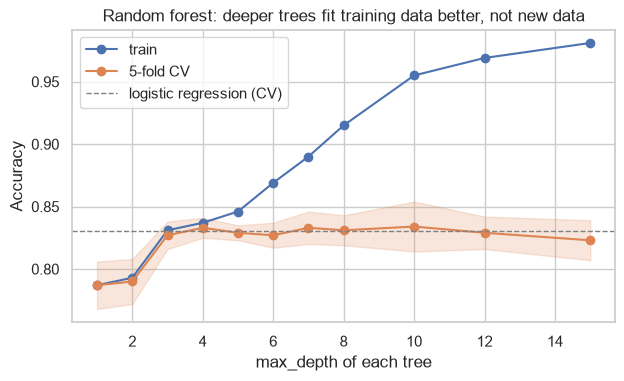

,max_depth,train,cv,cv_std
0,1,0.787,0.787,0.019
1,2,0.793,0.790,0.018
2,3,0.831,0.827,0.011
3,4,0.837,0.833,0.008
4,5,0.846,0.829,0.006
5,6,0.869,0.827,0.010
6,7,0.890,0.833,0.013
7,8,0.915,0.831,0.012
8,10,0.955,0.834,0.020
9,12,0.969,0.829,0.013


In [4]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15]
train_scores, cv_scores = validation_curve(
    make_model(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=N_THREADS)),
    X, y, param_name="model__max_depth", param_range=depths, cv=cv, scoring="accuracy",
)
depth_curve = pd.DataFrame({
    "max_depth": depths,
    "train": train_scores.mean(axis=1),
    "cv": cv_scores.mean(axis=1),
    "cv_std": cv_scores.std(axis=1),
}).round(3)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(depth_curve["max_depth"], depth_curve["train"], marker="o", label="train")
ax.plot(depth_curve["max_depth"], depth_curve["cv"], marker="o", label="5-fold CV")
ax.fill_between(depth_curve["max_depth"], depth_curve["cv"] - depth_curve["cv_std"],
                depth_curve["cv"] + depth_curve["cv_std"], alpha=0.2, color="C1")
ax.axhline(results["Logistic regression"]["test_score"].mean(), ls="--", c="grey", lw=1,
           label="logistic regression (CV)")
ax.set_xlabel("max_depth of each tree")
ax.set_ylabel("Accuracy")
ax.set_title("Random forest: deeper trees fit training data better, not new data")
ax.legend()
save_fig(fig, "rf_depth_curve")
plt.show()
depth_curve

Shallow trees **underfit**: both curves are low. As depth grows the training curve keeps rising, while the CV curve
flattens and then stops improving. The widening gap between the two curves is overfitting. This is the
*bias-variance trade-off*: more flexibility lowers the error from a too-simple model (bias) but raises the error from
learning noise in the particular training rows (variance).

## 4. Tuning with nested cross-validation

**The trap:** if we try 20 settings, score each on our 5 folds and report the best score, that score is too
optimistic. We picked the setting *because* it happened to do well on exactly these folds.

**Nested CV** keeps the choice honest:
- **Inner loop** (`GridSearchCV`, 4 folds of the training part): tries every setting and picks the best one.
- **Outer loop** (our usual 5 folds): scores the whole procedure *search, then refit with the best setting* on
  rows the search never saw.

The outer score estimates how well "tune, then train" works on new data. Different outer folds may pick
different settings; if they agree, the choice is stable.

In [5]:
inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)

rf_grid = {
    "model__max_depth": [4, 6, 8, None],
    "model__min_samples_leaf": [1, 3, 6],
    "model__max_features": ["sqrt", 0.5],
}
rf_search = GridSearchCV(
    make_model(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=N_THREADS)),
    rf_grid, cv=inner_cv, scoring="accuracy",
)

xgb_grid = {
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.03, 0.1],
    "model__n_estimators": [100, 300],
    "model__min_child_weight": [1, 5],
}
xgb_search = GridSearchCV(
    make_model(XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=N_THREADS)),
    xgb_grid, cv=inner_cv, scoring="accuracy",
)
print(f"Random forest: {len(ParameterGrid(rf_grid))} settings, XGBoost: {len(ParameterGrid(xgb_grid))} settings")

Random forest: 24 settings, XGBoost: 24 settings


In [6]:
evaluate("Random forest (tuned)", rf_search)
evaluate("XGBoost (tuned)", xgb_search);

Random forest (tuned)  CV accuracy 0.831 ± 0.013   (train 0.895)


XGBoost (tuned)        CV accuracy 0.832 ± 0.025   (train 0.886)


In [7]:
def chosen_params(name):
    """Setting picked by the inner search in each outer fold."""
    rows = [
        {key.replace("model__", ""): value for key, value in search.best_params_.items()}
        for search in results[name]["estimator"]
    ]
    return pd.DataFrame(rows, index=[f"fold {i + 1}" for i in range(len(rows))])


display(chosen_params("Random forest (tuned)"))
chosen_params("XGBoost (tuned)")

,max_depth,max_features,min_samples_leaf
fold 1,8.0,0.5,1
fold 2,4.0,sqrt,1
fold 3,NaN,sqrt,3
fold 4,8.0,0.5,3
fold 5,8.0,0.5,1


,learning_rate,max_depth,min_child_weight,n_estimators
fold 1,0.03,4,1,300
fold 2,0.03,2,1,300
fold 3,0.03,4,5,300
fold 4,0.10,4,5,100
fold 5,0.10,3,1,100


## 5. Comparison

In [8]:
summary = pd.DataFrame({
    name: {
        "cv_mean": s["test_score"].mean(),
        "cv_std": s["test_score"].std(),
        "train_mean": s["train_score"].mean(),
    }
    for name, s in results.items()
}).T
summary["train_cv_gap"] = summary["train_mean"] - summary["cv_mean"]
summary = summary.round(4)

# Keep the rows from earlier notebooks and replace the ones scored again here
all_results = pd.read_csv(REPORT_DIR / "cv_results.csv", index_col="model")
all_results = pd.concat([all_results.drop(index=summary.index, errors="ignore"), summary])
all_results.to_csv(REPORT_DIR / "cv_results.csv", index_label="model")
all_results.sort_values("cv_mean", ascending=False)

,cv_mean,cv_std,train_mean,train_cv_gap
XGBoost (tuned),0.8316,0.0248,0.8864,0.0548
Random forest (tuned),0.8305,0.0128,0.8945,0.0640
Logistic regression,0.8305,0.0099,0.8339,0.0034
XGBoost (default),0.8215,0.0356,0.9750,0.1535
Random forest (default),0.8215,0.0188,0.9888,0.1673
Gender rule,0.7868,0.0188,0.7868,0.0000
Majority class,0.6162,0.0023,0.6162,-0.0000


In [9]:
fold_scores = pd.DataFrame({name: s["test_score"] for name, s in results.items()})
fold_scores.index = [f"fold {i + 1}" for i in range(len(fold_scores))]
for name in ["Random forest (tuned)", "XGBoost (tuned)"]:
    fold_scores[f"{name} - logreg"] = fold_scores[name] - fold_scores["Logistic regression"]
fold_scores.round(3)

,Logistic regression,Random forest (default),XGBoost (default),Random forest (tuned),XGBoost (tuned),Random forest (tuned) - logreg,XGBoost (tuned) - logreg
fold 1,0.844,0.844,0.860,0.849,0.866,0.006,0.022
fold 2,0.826,0.809,0.837,0.820,0.843,-0.006,0.017
fold 3,0.815,0.792,0.758,0.820,0.798,0.006,-0.017
fold 4,0.837,0.837,0.809,0.843,0.843,0.006,0.006
fold 5,0.831,0.826,0.843,0.820,0.809,-0.011,-0.022


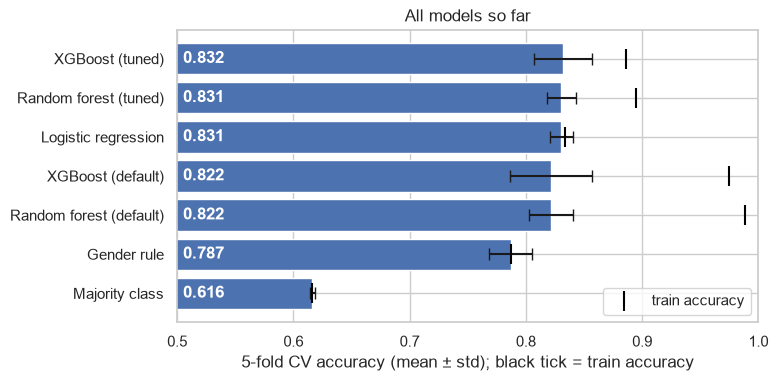

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
order = all_results.sort_values("cv_mean").index
ax.barh(order, all_results.loc[order, "cv_mean"], xerr=all_results.loc[order, "cv_std"], capsize=4)
ax.scatter(all_results.loc[order, "train_mean"], range(len(order)), marker="|", s=200, c="black",
           label="train accuracy", zorder=3)
for i, name in enumerate(order):
    ax.text(0.505, i, f"{all_results.loc[name, 'cv_mean']:.3f}", va="center", color="white", weight="bold")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("5-fold CV accuracy (mean ± std); black tick = train accuracy")
ax.set_title("All models so far")
ax.legend(loc="lower right")
save_fig(fig, "model_comparison")
plt.show()

With only ~178 passengers per validation fold, one passenger is worth 0.56 percentage points. Differences of one
or two points between models are within the fold-to-fold noise (the ± values), so the fold-by-fold table matters
more than the ranking of the means.

## 6. Error analysis: does a tree model fix the interaction?

In [11]:
best_tree = all_results.loc[["Random forest (tuned)", "XGBoost (tuned)"], "cv_mean"].idxmax()
best_search = rf_search if best_tree.startswith("Random forest") else xgb_search
print(f"Best tree model by CV: {best_tree}")



def out_of_fold(name):
    """Predict every row with the fold model that did not see it (reuses the models fitted in `evaluate`)."""
    pred = pd.Series(0, index=X.index)
    for fold_model, (_, valid_idx) in zip(results[name]["estimator"], cv.split(X, y)):
        pred.iloc[valid_idx] = fold_model.predict(X.iloc[valid_idx])
    return pred


oof = pd.DataFrame({name: out_of_fold(name) for name in ["Logistic regression", best_tree]})
group_accuracy = pd.concat(
    {name: train.assign(correct=(oof[name] == y)).pivot_table(
        index="Gender", columns="Pclass", values="correct", aggfunc="mean")
     for name in oof.columns},
    axis=0,
).round(3)
group_accuracy

Best tree model by CV: XGBoost (tuned)


Pclass                          1      2      3
                    Gender                     
Logistic regression female  0.968  0.895  0.653
                    male    0.631  0.926  0.893
XGBoost (tuned)     female  0.968  0.921  0.639
                    male    0.648  0.907  0.896

In [12]:
group_rates = train.assign(**{f"pred: {name}": oof[name] for name in oof.columns})
group_rates = group_rates.groupby(["Gender", "Pclass"]).agg(
    count=("Survived", "size"),
    true_rate=("Survived", "mean"),
    **{f"rate {name}": (f"pred: {name}", "mean") for name in oof.columns},
).round(3)
group_rates

count  true_rate  rate Logistic regression  \
Gender Pclass                                               
female 1          94      0.968                     1.000   
       2          76      0.921                     0.974   
       3         144      0.500                     0.806   
male   1         122      0.369                     0.197   
       2         108      0.157                     0.083   
       3         347      0.135                     0.029   

               rate XGBoost (tuned)  
Gender Pclass                        
female 1                      1.000  
       2                      1.000  
       3                      0.583  
male   1                      0.279  
       2                      0.102  
       3                      0.032

In [13]:
disagree = oof[oof.iloc[:, 0] != oof.iloc[:, 1]]
print(f"The two models disagree on {len(disagree)} of {len(oof)} passengers "
      f"({len(disagree) / len(oof):.1%}).")
for name in oof.columns:
    print(f"  right on the disagreements: {name:<22} {(disagree[name] == y[disagree.index]).mean():.3f}")

The two models disagree on 61 of 891 passengers (6.8%).
  right on the disagreements: Logistic regression    0.492
  right on the disagreements: XGBoost (tuned)        0.508


## 7. Which input columns matter?

**Permutation importance:** shuffle one input column in the validation fold, so its link to the target is broken,
and measure how much accuracy drops. A big drop means the model relies on that column. It is computed on the
**held-out** fold of each outer split (with the fold's tuned model), so it reflects what helps on new data, not
what the model memorised. Columns are the raw ones the pipeline receives, so `Name` stands for the title extracted
from it and `SibSp`/`Parch` for the family type.

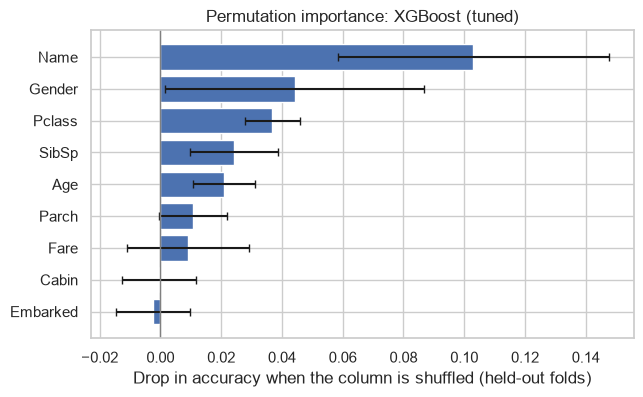

,mean,std
Name,0.1030,0.0447
Gender,0.0441,0.0426
Pclass,0.0369,0.0092
SibSp,0.0242,0.0144
Age,0.0210,0.0101
Parch,0.0108,0.0111
Fare,0.0090,0.0201
Cabin,-0.0005,0.0122
Embarked,-0.0025,0.0122


In [14]:
input_columns = ["Pclass", "Gender", "Name", "Age", "SibSp", "Parch", "Fare", "Cabin", "Embarked"]
fold_importances = []
for fold_model, (_, valid_idx) in zip(results[best_tree]["estimator"], cv.split(X, y)):
    result = permutation_importance(
        fold_model.best_estimator_, X.iloc[valid_idx], y.iloc[valid_idx],
        n_repeats=20, random_state=SEED, scoring="accuracy",
    )
    fold_importances.append(pd.Series(result.importances_mean, index=X.columns)[input_columns])
importance = pd.concat(fold_importances, axis=1)
importance = pd.DataFrame({"mean": importance.mean(axis=1), "std": importance.std(axis=1)})
importance = importance.sort_values("mean")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], capsize=3)
ax.axvline(0, c="grey", lw=1)
ax.set_xlabel("Drop in accuracy when the column is shuffled (held-out folds)")
ax.set_title(f"Permutation importance: {best_tree}")
save_fig(fig, "trees_permutation_importance")
plt.show()
importance.sort_values("mean", ascending=False).round(4)

`Gender` and `Name` (title) overlap: both separate men from women. Shuffling one of them hurts less than it
would on its own, because the other still carries most of the same information. Permutation importance shows
what the model *uses*, which is not the same as what *causes* survival.

## 8. Submission file

In [15]:
best_search.fit(X, y)
final_params = {key.replace("model__", ""): value for key, value in best_search.best_params_.items()}
print(f"{best_tree}: setting chosen on all 891 passengers: {final_params}")

test_pred = best_search.predict(test)
submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": test_pred})
assert submission.shape == (418, 2) and submission["Survived"].isin([0, 1]).all()

file_name = "03_rf.csv" if best_tree.startswith("Random forest") else "03_xgb.csv"
submission.to_csv(SUBMISSION_DIR / file_name, index=False)

logreg_submission = pd.read_csv(SUBMISSION_DIR / "02_logreg.csv")
same = (submission["Survived"].to_numpy() == logreg_submission["Survived"].to_numpy()).mean()
print(f"Saved {file_name}. Predicted survival rate on test: {submission['Survived'].mean():.3f}; "
      f"agrees with the logistic regression submission on {same:.1%} of test passengers.")

XGBoost (tuned): setting chosen on all 891 passengers: {'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 100}
Saved 03_xgb.csv. Predicted survival rate on test: 0.388; agrees with the logistic regression submission on 95.2% of test passengers.


## 9. Findings

**Scores (5-fold stratified CV, same folds as notebook 02)**

| Model | CV accuracy | Train accuracy | Train − CV |
|---|---|---|---|
| Logistic regression | 0.831 ± 0.010 | 0.834 | 0.003 |
| Random forest (default) | 0.822 ± 0.019 | 0.989 | 0.167 |
| XGBoost (default) | 0.822 ± 0.036 | 0.975 | 0.154 |
| Random forest (tuned, nested CV) | 0.831 ± 0.013 | 0.895 | 0.064 |
| XGBoost (tuned, nested CV) | **0.832 ± 0.025** | 0.886 | 0.055 |

**Default trees overfit.** Both ensembles memorise the training passengers (97–99% train accuracy) and score
about one point *below* logistic regression on new passengers.

**Depth curve.** Random forest CV accuracy climbs from 0.787 (depth 1) to ~0.83 at depth 3–4 and then stays flat
between 0.823 and 0.834, while training accuracy keeps rising to 0.98. Everything beyond depth ~4 is spent on
memorising, not on generalising.

**Tuning closes the gap but does not open a lead.** With nested CV the tuned models land at 0.831 (RF) and 0.832
(XGBoost), level with logistic regression. Fold by fold the differences to logistic regression range from −2.2 to
+2.2 points with mixed signs (each tree model wins 3 of 5 folds). A 0.1-point difference in the mean is less than
one passenger per fold: this is a **tie**. XGBoost's fold scores also vary 2.5 times as much (± 0.025 vs ± 0.010).

**The chosen settings are unstable.** Different outer folds picked different settings (RF depth 4, 8 or unlimited;
XGBoost learning rate 0.03 or 0.1, depth 2–4, 100 or 300 trees), and the search on all 891 passengers picked yet
another one. Many settings are about equally good, so there is little to gain from more tuning.

**Trees did not fix the gender × class interaction.** For women in 3rd class XGBoost is less optimistic than
logistic regression (predicted survival 58% vs 81%, truth 50%) but still right for only 64% of them (logistic
regression 65%). For men in 1st class it is 65% vs 63%. The two models disagree on 61 passengers (6.8%) and each
is right on about half of those: the disagreements look like noise, not a systematic advantage.

**What the tuned XGBoost uses** (permutation importance, held-out folds): `Name` (the title) 0.103, `Gender`
0.044, `Pclass` 0.037, then the family columns and `Age` (0.01–0.02). `Cabin` and `Embarked` are indistinguishable
from zero. The title is the single most useful column because it encodes gender *and* whether a male passenger
is a boy.

**Conclusion.** With these 20 features, about 83% CV accuracy looks like a ceiling that the choice of model does
not move. A more complex model only adds variance. Further gains need **new information** (for example whether
other members of a passenger's family or ticket group survived, computed inside the folds to avoid leakage), not
a more flexible learner. Given equal accuracy, logistic regression is the safer choice: lower variance, faster,
and its weights can be read.

**Submission.** `submissions/03_xgb.csv` (tuned XGBoost refitted on all passengers) agrees with the logistic
regression submission on 95.2% of the test passengers. Submitting both shows how much the public leaderboard
moves for practically equal models.